# Summarize abundance results

In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

In [2]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"

## 1. Count assayed genes and alleles from median and mean calculation

In [3]:
abun_median = pl.read_csv(f'{dualipa_outputs}/DUALIPA_median_zscore.csv', infer_schema_length=1000000).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele")
).filter(~pl.col("zscore_log2").is_null()).rename(
    {"zscore_log2": "zscore_log2fc_median_norm_by_each_wt"}
)

num_alleles = len(abun_median.select("gene_allele").to_series().unique().to_list())
num_genes = len(abun_median.select("symbol").to_series().unique().to_list())
print(f"{num_alleles} variants across {num_genes} genes were assayed for aggregation by median.")

782 variants across 87 genes were assayed for aggregation by median.


In [4]:
abun_mean = pl.read_csv(f'{dualipa_outputs}/DUALIPA_mean_zscore.csv', infer_schema_length=1000000).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele"),
).filter(
    ~pl.col("zscore_log2").is_null()
).rename(
    {
        "allele_wt_log2fc_zscore": "zscore_log2fc_mean_norm_by_all_wt_mean",
        "zscore_log2": "zscore_log2fc_mean_norm_by_each_wt"
    }
)

num_alleles = len(abun_mean.select("gene_allele").to_series().unique().to_list())
num_genes = len(abun_mean.select("symbol").to_series().unique().to_list())
print(f"{num_alleles} variants across {num_genes} genes were assayed for aggregation by mean.")

804 variants across 93 genes were assayed for aggregation by mean.


__Mean calculation preserved more genes and variants, since the WT median might more likely be zero.__

## 2. Investigate impact of log2 Z-score vs. fold-change z-score

The first set of results were z-scores computed based on raw GFP:mCherry ratios. However, the raw ratios are highly skewed and it makes more sense to do the analysis on log-transformed ratios (log2FC). Here we investigate the impact of using a raw ratio vs. a log2FC. 

### 2.1 Median case

In [5]:
pDEST_DUAL_allele_df = abun_median.to_pandas()
sig_threshold = 1.96

clean_array = pDEST_DUAL_allele_df['zscore_median'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_median_norm_by_each_wt'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

Percentage of sig zscore values: 36.83%
Percentage of sig increase: 5.24%
Percentage of sig decrease: 31.59%
Percentage of sig zscore_log2 values: 39.51%
Percentage of sig increase: 2.56%
Percentage of sig decrease: 36.96%


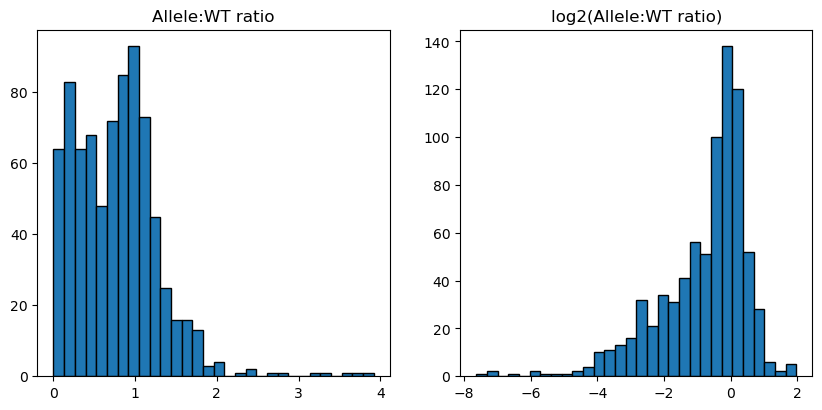

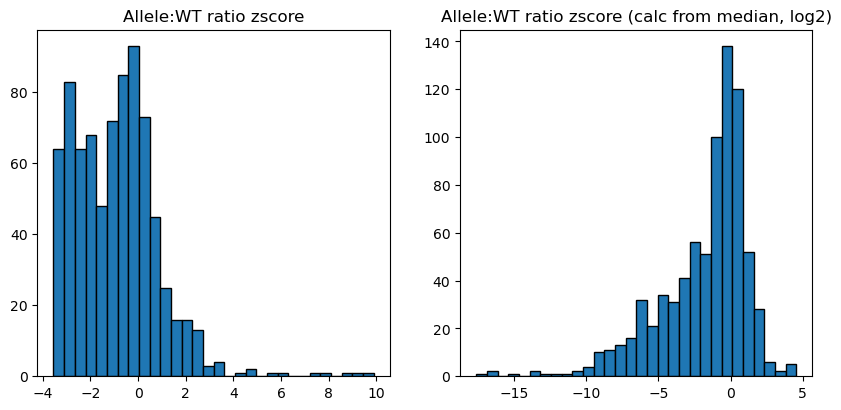

In [6]:
fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['allele_wt_ratio_median'], bins=30, edgecolor='black')
axes[0].set_title("Allele:WT ratio")

axes[1].hist(np.log2(pDEST_DUAL_allele_df['allele_wt_ratio_median']), bins=30, edgecolor='black')
axes[1].set_title("log2(Allele:WT ratio)")
plt.show()

fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['zscore_median'], bins=30, edgecolor='black')
axes[0].set_title("Allele:WT ratio zscore")

axes[1].hist(pDEST_DUAL_allele_df['zscore_log2fc_median_norm_by_each_wt'], bins=30, edgecolor='black')
axes[1].set_title("Allele:WT ratio zscore (calc from median, log2)")
plt.show()

### 2.2 Mean case

Percentage of sig zscore_log2 values: 52.24%
Percentage of sig increase: 8.08%
Percentage of sig decrease: 44.15%
Percentage of sig zscore_log2 values: 37.94%
Percentage of sig increase: 3.36%
Percentage of sig decrease: 34.58%


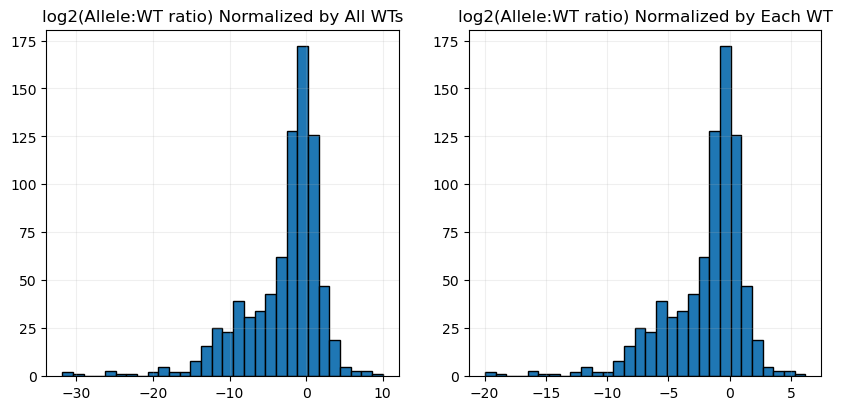

In [7]:
pDEST_DUAL_allele_df = abun_mean.to_pandas()
sig_threshold = 1.96

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_all_wt_mean'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

clean_array = pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_each_wt'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > sig_threshold) | (clean_array < -sig_threshold)).mean() * 100
percent_high = (clean_array > sig_threshold).mean() * 100
percent_low = (clean_array < -sig_threshold).mean() * 100
print(f"Percentage of sig zscore_log2 values: {percent_outside_bounds:.2f}%")
print(f"Percentage of sig increase: {percent_high:.2f}%")
print(f"Percentage of sig decrease: {percent_low:.2f}%")

fig, axes = plt.subplots(1,2,figsize=(10,4.5))
axes[0].hist(pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_all_wt_mean'], bins=30, edgecolor='black')
axes[0].set_title("log2(Allele:WT ratio) Normalized by All WTs")
axes[1].hist(pDEST_DUAL_allele_df['zscore_log2fc_mean_norm_by_each_wt'], bins=30, edgecolor='black')
axes[1].set_title("log2(Allele:WT ratio) Normalized by Each WT")
axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.show()

The distributions of ```zscore_log2fc_mean_norm_by_all_wt_mean``` and ```zscore_log2fc_mean_norm_by_each_wt``` are almost the same, except for the spread (variation). Normalization by each gene would be more biologically relevant, as it initially captured more variations between WT-WT wells, which led to smaller spread in the Z-score of log2FC's when it was calculated by dividing the std(wt-wt variation).

Go with ```zscore_log2fc_mean_norm_by_each_wt``` eventually.

In [8]:
abun_merged = abun_mean.join(
    abun_median.select(["orf_id", "mut_id"]+[c for c in abun_median.columns if c not in abun_mean.columns]),
    on=["orf_id", "mut_id"],
    how="left"
)

## 3. Pick the final metric for DUAL-IPA abundance change detection

In [9]:
"""
    Compare three metrics for pathogenic-vs-benign separation using Polars
    - Balanced Accuracy
    - AUCPRC
    - Balanced-AUPRC
"""

from sklearn.metrics import balanced_accuracy_score, average_precision_score, precision_recall_curve, auc, roc_auc_score
def compute_balanced_auprc(auprc: float, prior: float) -> float:
    """
    Balanced AUPRC (bAUPRC) correcting for class imbalance.
    prior = fraction of positives in the dataset.
    """
    return (auprc * (1 - prior)) / ((auprc * (1 - prior)) + ((1 - auprc) * prior))

# -------------------------------------------------
# 1.  Load your Polars dataframe (replace with real path)
# -------------------------------------------------
df = abun_merged.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(1)
    .otherwise(0)
    .alias("clinvar_label")
)

# -------------------------------------------------
# 2.  Evaluation helper
# -------------------------------------------------
def evaluate_metric(df, col):
    df_clean = df.drop_nulls(subset=col)
    y = df_clean["clinvar_label"].to_numpy()
    scores = df_clean[col].to_numpy()
    prior = y.mean()

    # Balanced accuracy via grid search
    best_ba, best_t = 0, None
    for t in np.unique(scores):
        pred = (scores <= t).astype(int)
        ba = balanced_accuracy_score(y, pred)
        if ba > best_ba:
            best_ba, best_t = ba, t

    # AUROC and AUCPRC
    auroc  = roc_auc_score(y, -scores)
    auprc  = average_precision_score(y, -scores)
    bauprc = compute_balanced_auprc(auprc, prior)
    return {
        "bal_acc": round(best_ba, 5),
        "auroc":   round(auroc, 5),
        "auprc":   round(auprc, 5),
        "bauprc":  round(bauprc, 5),
        "threshold": round(best_t, 5),
    }

# -------------------------------------------------
# 3.  Run for each metric column
# -------------------------------------------------
metric_cols = [
    "zscore_log2fc_mean_norm_by_each_wt",
    "zscore_log2fc_median_norm_by_each_wt",
]

results = {col: evaluate_metric(df, col) for col in metric_cols}

# -------------------------------------------------
# 4.  Report
# -------------------------------------------------
for k, v in results.items():
    print(f"{k}: {v}")

print("\nBest balanced accuracy ->", max(results, key=lambda k: results[k]["bal_acc"]))
print("Best AUROC             ->", max(results, key=lambda k: results[k]["auroc"]))
print("Best AUCPRC            ->", max(results, key=lambda k: results[k]["auprc"]))
print("Best bAUPRC            ->", max(results, key=lambda k: results[k]["bauprc"]))

zscore_log2fc_mean_norm_by_each_wt: {'bal_acc': np.float64(0.67656), 'auroc': np.float64(0.69494), 'auprc': np.float64(0.92982), 'bauprc': np.float64(0.72266), 'threshold': np.float64(-0.76013)}
zscore_log2fc_median_norm_by_each_wt: {'bal_acc': np.float64(0.66737), 'auroc': np.float64(0.68439), 'auprc': np.float64(0.92994), 'bauprc': np.float64(0.71279), 'threshold': np.float64(-1.34632)}

Best balanced accuracy -> zscore_log2fc_mean_norm_by_each_wt
Best AUROC             -> zscore_log2fc_mean_norm_by_each_wt
Best AUCPRC            -> zscore_log2fc_median_norm_by_each_wt
Best bAUPRC            -> zscore_log2fc_mean_norm_by_each_wt


In [10]:
abun_merged = abun_merged.with_columns(
    pl.col("zscore_log2fc_mean_norm_by_each_wt").alias("dualipa_abun_score")
)
df_clinvar = abun_merged.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(1)
    .otherwise(0)
    .alias("clinvar_label")
)
abun_merged.shape

(804, 560)

## 5. LLR Calculation

### 5.1 Output the scores for LLR calculation by R scripts

In [12]:
abun_merged.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("dualipa_abun_score").alias("score"),
    pl.col("gene_allele").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "dualipa_abun_score", "gene_allele", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/DUALIPA_referenceSet.csv")

abun_merged.with_columns(
    pl.col("dualipa_abun_score").alias("score"),
    pl.col("gene_allele").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/DUALIPA_allScores.csv")

In [14]:
# abun_merged.filter(
#     pl.col("clinvar_clnsig_clean")=="2_Benign"
# ).sort("dualipa_abun_score")

In [15]:
# abun_merged.with_columns(
#     pl.col("symbol").alias("gene"),
#     pl.col("aa_change").alias("variant"),
#     pl.col("dualipa_abun_score").alias("score"),
#     (
#         pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
#         .then(pl.lit("P"))
#         .when(pl.col("clinvar_clnsig_clean")=="2_Benign")
#         .then(pl.lit("B"))
#         .otherwise(pl.lit(""))
#     ).alias("class")
# ).select(
#     pl.col(["gene","variant","score","class"])
# ).write_csv("../3_outputs/DUALIPA_allScores_acmgscaler.csv")

### 5.2 Run the LLR calculation

* Successfully run the bandwidths of bcv and nrd0 using the default epanechnikov kernel, by playing around with the outlierSuppression param to set the LLR to start from 0

* ```nrd0``` bandwidth leads to the smoothest curve of LLR, and was picked for the final result

In [33]:
%%bash
source ~/software/anaconda3/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_bcv" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_bcv.log" --bandwidth "bcv" --printTransitions --outlierSuppression 0.2
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_nrd0" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --outlierSuppression 0.1

## Non-smooth, failed bandwidth:
## No need to run any more
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_default" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_default.log" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_nrd" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_sj" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_sj.log" --printTransitions --bandwidth "SJ"
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/DUALIPA_allScores.csv ../3_outputs/DUALIPA_referenceSet.csv --outfile "../3_outputs/calcLLR/DUALIPA_LLR_score_nrd" --logfile "../3_outputs/calcLLR/DUALIPA_LLR_nrd.log" --bandwidth "nrd" --printTransitions

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-24_21:03:17 INFO: Reading input 
2025-07-24_21:03:17 INFO: Calculating densties 
2025-07-24_21:03:18 INFO: Drawing LLR plot 
2025-07-24_21:03:18 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-24_21:03:19 INFO: Category transitions:  
-12.090 : none -> patho.support
-9.369 : patho.support -> patho.moderate
-7.668 : patho.moderate -> patho.strong
-5.339 : patho.strong -> patho.moderate
-4.763 : patho.moderate -> patho.support
-4.319 : patho.support -> none
0.313 : none -> benign.support
1.491 : benign.support -> none
2.485 : none -> patho.support
2.694 : patho.support -> patho.moderate
3.244 : patho.moderate -> patho.support
5.102 : patho.support -> none
2025-07-24_21:03:19 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-24_21:03:19 INFO: Writing output to file  ../3_outputs/calcLLR/DUALIPA_LLR_score_bcv.csv 
2025-07-24_21:03:19 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-07-24_21:03:19 INFO: Reading input 
2025-07-24_21:03:19 INFO: Calculating densties 
2025-07-24_21:03:20 INFO: Drawing LLR plot 
2025-07-24_21:03:20 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-07-24_21:03:21 INFO: Category transitions:  
-13.216 : none -> patho.support
-11.175 : patho.support -> patho.moderate
-8.636 : patho.moderate -> patho.strong
-5.182 : patho.strong -> patho.moderate
-4.790 : patho.moderate -> patho.support
-4.371 : patho.support -> none
-0.524 : none -> benign.support
0.863 : benign.support -> none
2.171 : none -> patho.support
2.407 : patho.support -> patho.moderate
2.485 : patho.moderate -> patho.strong
2.694 : patho.strong -> patho.moderate
4.605 : patho.moderate -> patho.support
5.730 : patho.support -> none
2025-07-24_21:03:21 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-07-24_21:03:21 INFO: Writing output to file  ../3_outputs/calcLLR/DUALIPA_LLR_score_nrd0.csv 
202

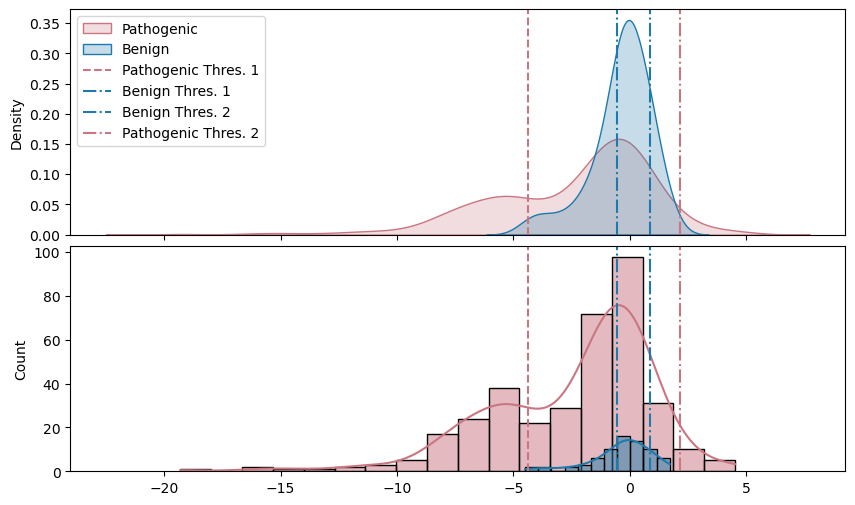

In [11]:
path_thres, benign_thres_bottom, benign_thres_top, path_thres_2 = -4.371, -0.524, 0.863, 2.171

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=abun_merged.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["dualipa_abun_score"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=abun_merged.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["dualipa_abun_score"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].axvline(x=benign_thres_bottom, color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres. 1')
axes[0].axvline(x=benign_thres_top, color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres. 2')
axes[0].axvline(x=path_thres_2, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='-.', label='Pathogenic Thres. 2')
axes[0].legend()

sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["dualipa_abun_score"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(abun_merged.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["dualipa_abun_score"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[1].axvline(x=benign_thres_bottom, color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres. 1')
axes[1].axvline(x=benign_thres_top, color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], linestyle='-.', label='Benign Thres. 2')
axes[1].axvline(x=path_thres_2, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='-.', label='Pathogenic Thres. 2')
plt.subplots_adjust(hspace=.05)
plt.show()

## 6. Final Output

In [12]:
abun_merged = abun_merged.with_columns(
    pl.when((pl.col("dualipa_abun_score")<=path_thres)|((pl.col("dualipa_abun_score")>=path_thres_2)))
    .then(pl.lit("Y"))
    .when((pl.col("dualipa_abun_score")>=benign_thres_bottom)&(pl.col("dualipa_abun_score")<=benign_thres_top))
    .then(pl.lit("N"))
    .otherwise(pl.lit("Uncertain"))
    .alias("dualipa_abun_change"),
    pl.when((pl.col("dualipa_abun_score")<0))
    .then(pl.lit("Decrease"))
    .when((pl.col("dualipa_abun_score")>0))
    .then(pl.lit("Increase"))
    .otherwise(pl.lit("No_Change"))
    .alias("dualipa_abun_chg_dir")
).with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
    pl.col("clinvar_clnsig_clean").fill_null("6_No_ClinVar")
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("RSA_Category"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("pLDDT_Category")
)

abun_merged.write_csv("../3_outputs/annotated_perturbation_scores.csv")

In [13]:
abun_merged.sort("dualipa_abun_score")["dualipa_abun_score","dualipa_abun_chg_dir","dualipa_abun_change"]

dualipa_abun_score,dualipa_abun_chg_dir,dualipa_abun_change
f64,str,str
-19.966896,"""Decrease""","""Y"""
-19.302944,"""Decrease""","""Y"""
-19.037495,"""Decrease""","""Y"""
-16.088844,"""Decrease""","""Y"""
-16.065235,"""Decrease""","""Y"""
…,…,…
4.35952,"""Increase""","""Y"""
4.4417,"""Increase""","""Y"""
4.530291,"""Increase""","""Y"""
